# Can a computer predict BatChat's favorite Batman stories?

*Undone* ranks **47th** of the 740 Batman stories on BatChat. Our best model guesses somewhere near **500th**. It knows who made the comic and when it came out, but it has no idea how a silent issue about grief reads.

[BatChat](https://comicsxf.com/batchat-rankings/) is a podcast where Matt Lazorwitz and Will Nevin have spent years reading and ranking Batman. This notebook asks how much of their taste a model can learn from names, dates, characters, and plot summaries, and what the books it gets wrong have in common.

**Rank 1 is best.** The hosts put *White Knight* at **#734 of 740**; the model, knowing only who made it and when, guesses around **#270**. We'll get to that. New to the data? Start with [Who Gets the Good Batman Stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) or [BatChat vs the Crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree).

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · snapshot of 21 October 2026*

In [1]:
from itertools import pairwise
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv")
issues = pd.read_csv(DATA / "issues.csv")
texts = pd.read_csv(DATA / "story_texts.csv")
N = len(stories)
y = stories["rank"].to_numpy(dtype=float)
print(f"{N} ranked stories, from {stories.title[0]} (#1) to {stories.title[N - 1]} (#{N})")

740 ranked stories, from Year One (#1) to Batman: Three Jokers #1-3 (#740)


## What the model gets to see

For each story, the model sees:

- **When:** cover year, number of issues, and how many days into the podcast's run it was discussed.
- **Format:** comic, graphic novel, prose, and so on.
- **Who:** the writers, pencilers, inkers, colorists, letterers, and editors of the selected story.
- **Cast:** the featured characters and antagonists.
- **Awards:** the creators' Eisner wins *before* the comic came out.

Each name becomes its own yes/no column: did this person work on it? Here are three rows of what the model sees (`New Earth`/`Prime Earth` are DC's continuity labels; `NaN` means unknown).

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = ["narrative_" + role for role in ROLES]
CAST = ["featured_entity_ids", "antagonists_entity_ids"]
WHEN = ["cover_year_start", "issue_count", "discussion_day"]
AWARDS = ["creator_eisner_personal_wins_pre_publication"]

X = stories[
    ["medium", "format_hint", "cover_year_start", "issue_count", *NAMES, *CAST, *AWARDS]
].copy()
dates = pd.to_datetime(stories.discussion_date)
X["discussion_day"] = (dates - dates.min()).dt.days
X[NAMES + CAST] = X[NAMES + CAST].fillna("")


def model(numbers=(), name_lists=(), text=None, forest=False):
    """Numbers are scaled, format is one-hot encoded, every name in a list becomes a 0/1 column,
    and `text` (a column name) becomes TF-IDF word weights."""
    features = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(numbers)),
        (OneHotEncoder(handle_unknown="ignore", min_frequency=3), ["medium", "format_hint"]),
        *[
            (CountVectorizer(token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=3), col)
            for col in name_lists
        ],
        *(
            [(TfidfVectorizer(stop_words="english", min_df=3, max_df=0.9, sublinear_tf=True), text)]
            if text
            else []
        ),
    )
    if forest:
        return make_pipeline(
            features,
            RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
        )
    return make_pipeline(features, RidgeCV(alphas=np.logspace(-1, 3, 9)))


X.head(3).T

,0,1,2
medium,comic,comic,comic
format_hint,unspecified,unspecified,unspecified
cover_year_start,1987.0,2000.0,2018.0
issue_count,4.0,1.0,3.0
narrative_writers,Frank Miller,Darwyn Cooke,Tom King
narrative_pencilers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_inkers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_colorists,Richmond Lewis,Darwyn Cooke,Elizabeth Breitweiser
narrative_letterers,Todd Klein,Jon Babcock,Clayton Cowles
narrative_editors,Dennis O'Neil,Mark Chiarello,Brittany Holzherr|Jamie S. Rich


## Testing fairly

Every prediction comes from a model that never saw that story: we split the list into five piles, and each pile is scored by a model trained on the other four. We also keep **linked stories in the same pile**: two arcs that share an issue (a crossover chapter, say), or stories the hosts covered in one episode. Otherwise, training on one chapter of an arc would make the next suspiciously easy.

Linked doesn't mean similar, though. One Halloween episode covered both *Red Rain* (**#6**) and *Superman and Batman vs. Vampires and Werewolves* (**#732**).

In [3]:
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))
print(
    f"{len(set(groups))} groups of linked stories; the biggest holds {pd.Series(groups).value_counts().max()}."
)

231 groups of linked stories; the biggest holds 13.


## Can we beat guessing the middle?

The laziest prediction is the average rank: put every story at about #370. We measure error in **rank places**: predicting #200 for the story at #100 misses by 100. Then we add information step by step. Two kinds of model: a **linear model** adds up points per name and date; a **random forest** is a crowd of decision trees that vote.

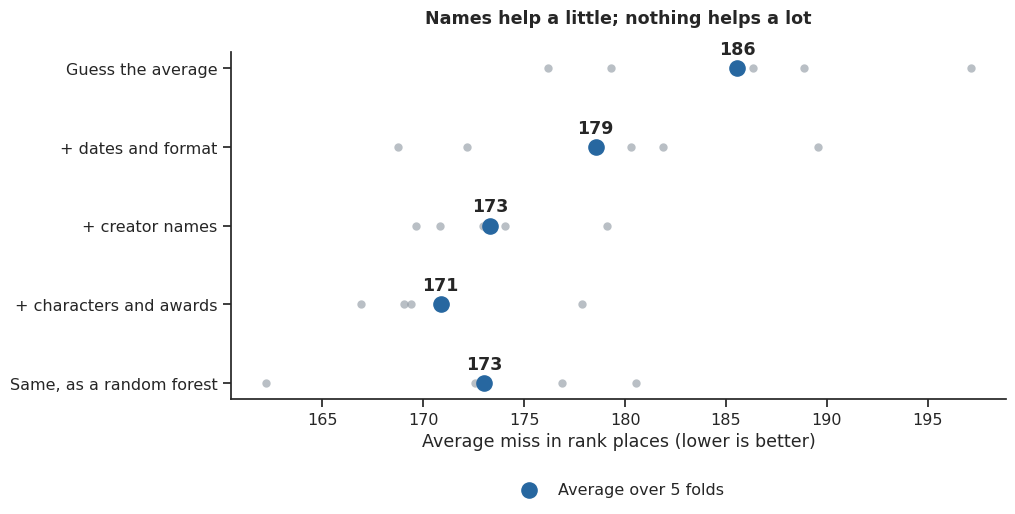

In [4]:
ladder = {
    "Guess the average": DummyRegressor(),
    "+ dates and format": model(WHEN),
    "+ creator names": model(WHEN, NAMES),
    "+ characters and awards": model(WHEN + AWARDS, NAMES + CAST),
    "Same, as a random forest": model(WHEN + AWARDS, NAMES + CAST, forest=True),
}
fold_errors = pd.DataFrame(
    {
        name: -cross_validate(m, X, y, cv=folds, scoring="neg_mean_absolute_error")["test_score"]
        for name, m in ladder.items()
    }
).melt(var_name="model", value_name="error")
errors = fold_errors.groupby("model", sort=False).error.mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(
    data=fold_errors, x="error", y="model", color=GREY, alpha=0.5, size=6, jitter=False, ax=ax
)
ax.scatter(errors, range(len(errors)), color=BLUE, s=120, zorder=3, label="Average over 5 folds")
for pos, value in enumerate(errors):
    ax.annotate(
        f"{value:.0f}",
        (value, pos),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontweight="bold",
    )
ax.set(
    xlabel="Average miss in rank places (lower is better)",
    ylabel="",
    title="Names help a little; nothing helps a lot\n",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()

Each step helps a little: about **8% less error** by the end than guessing the middle. But a typical story still lands about **170 places** from where the hosts put it, and the random forest does no better than the linear model. The grey dots are the five piles; they spread about as wide as the gains, so the small steps are noise.

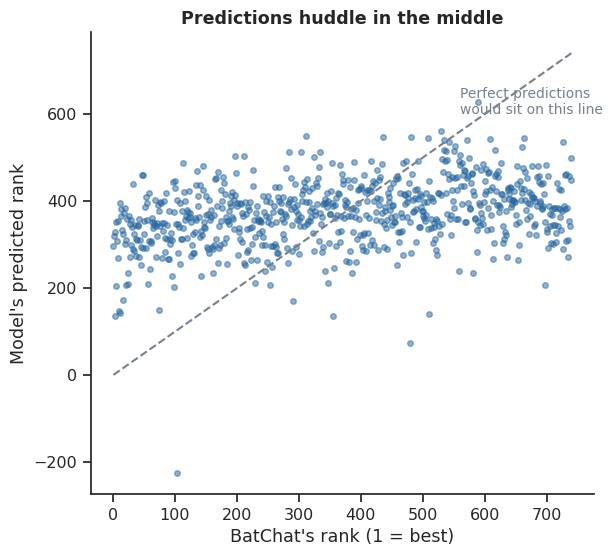

In [5]:
best = "+ characters and awards"
predictions = {
    name: cross_val_predict(ladder[name], X, y, cv=folds)
    for name in [best, "Same, as a random forest"]
}
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y, predictions[best], s=16, alpha=0.5, color=BLUE)
ax.plot([1, N], [1, N], ls="--", color=GREY)
ax.annotate("Perfect predictions\nwould sit on this line", (560, 600), color=GREY, fontsize=10)
ax.set(
    xlabel="BatChat's rank (1 = best)",
    ylabel="Model's predicted rank",
    title="Predictions huddle in the middle",
)
plt.show()

Below, each dot is a story: BatChat's rank across, the model's guess up. The model plays it safe. It pulls favorites down toward the middle and lifts the stories at the bottom. A model that only knows names and dates can't tell a career-best book from an off month.

## What about an artist the model has never seen?

Normal testing lets the model learn an artist from their other books. Here we hide the five busiest pencilers, one at a time: all their stories leave the training set, and the model has to rank them cold.

In [6]:
rows = []
names = X[NAMES].apply(lambda col: col.str.split("|").map(set))
artists = names.narrative_pencilers.explode().value_counts().head(5).index
for artist in artists:
    involved = names.apply(lambda col: col.map(lambda s: artist in s)).any(axis=1)
    test = names.narrative_pencilers.map(lambda s: artist in s).to_numpy()
    train = (~involved & ~pd.Series(groups).isin(groups[test])).to_numpy()
    fitted = ladder[best].fit(X[train], y[train])
    rows.append(
        {
            "Artist": artist,
            "Stories": test.sum(),
            "Their median rank": np.median(y[test]),
            "Model's miss (rank places)": mean_absolute_error(y[test], fitted.predict(X[test])),
            "Average-guess miss (rank places)": mean_absolute_error(
                y[test], np.full(test.sum(), y[train].mean())
            ),
        }
    )
pd.DataFrame(rows).set_index("Artist").round(0)

,Stories,Their median rank,Model's miss (rank places),Average-guess miss (rank places)
Artist,,,,
Jim Aparo,24,364.0,157.0,169.0
Bob Kane,20,544.0,139.0,190.0
Norm Breyfogle,19,324.0,138.0,140.0
Neal Adams,16,398.0,163.0,173.0
Kelley Jones,16,312.0,214.0,212.0


The table shows how far off the model is for each artist's books versus just guessing the average. Bob Kane is the model's best case: knowing a story is from the 1940s already says a lot, so it misses his books by **139 places** against **190** for the average guess. For Kelley Jones it does slightly *worse* than guessing. His books run from *Red Rain* (#6) to *Unseen* (#716), and nothing in the metadata tells them apart.

## The interesting misses

These are the stories where the model and the random forest are both most wrong in the same direction. They are the books the metadata can't explain, and probably the most fun to argue about.

In [7]:
misses = stories[["title", "rank"]].assign(
    ridge=predictions[best].round(), forest=predictions["Same, as a random forest"].round()
)
misses["surprise"] = misses.ridge - misses["rank"]
both_agree = np.sign(misses.surprise) == np.sign(misses.forest - misses["rank"])
columns = {
    "title": "Story",
    "rank": "BatChat rank",
    "ridge": "Model guessed",
    "forest": "Forest guessed",
}
for caption, pick in [
    ("The hosts liked these far more than the metadata suggests:", misses[both_agree].nlargest),
    ("…and these far less:", misses[both_agree].nsmallest),
]:
    print(caption)
    display(pick(8, "surprise")[list(columns)].rename(columns=columns).set_index("Story"))

The hosts liked these far more than the metadata suggests:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Undone,47,460.0,505.0
Night of the Stalker,48,459.0,466.0
The Dark Knight Returns: The Last Crusade,33,440.0,395.0
The Joker’s Five-Way Revenge,11,395.0,411.0
The Joker/ The Joker Returns,114,488.0,526.0
Kingdom Come #1-4,13,381.0,327.0
The Garden of Earthly Delights,20,384.0,352.0
There is Hope in Crime Alley,58,419.0,438.0


…and these far less:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Knightquest: The Search,697,208.0,306.0
Batman: White Knight #1-8,734,272.0,285.0
Batman/Green Arrow: The Poison Tomorrow,727,290.0,282.0
Superman and Batman Vs. Vampires and Werewolves,732,308.0,292.0
Odyssey,735,311.0,381.0
The Wedding,703,292.0,367.0
The Last Batman Story–?,711,302.0,341.0
Batman: Unseen #1-5,716,307.0,326.0


*Undone* tops the "liked more" list, alongside *The Joker's Five-Way Revenge* (#11), *Kingdom Come* (#13), and *The Last Crusade* (#33).

**Going the other way: *White Knight*. BatChat #734; model #272.** Sean Murphy, the Joker, 2017: everything the metadata likes. Also *Unseen* and *Knightquest: The Search*: well-known teams and characters, but books the hosts didn't enjoy.

If you're Matt or Will, this table is probably the most interesting part of the notebook: the books where your taste is hardest to predict from who made them.

## Does knowing the plot help?

The dataset has about **700,000 words of fan-written plot summaries** from the DC wiki. We turn each summary into a bag of weighted words: a word counts for more when it recurs in one summary and for less when every summary uses it (the technique is called TF-IDF).

This captures names and subjects. It loses word order, pacing, and above all the pictures. About a fifth of the stories, mostly recent ones, have no summary at all.

In [8]:
available = texts[texts.text_status.eq("available")].drop_duplicates(["story_id", "synopsis_text"])
X["plot_text"] = stories.story_id.map(
    available.groupby("story_id").synopsis_text.agg(" ".join)
).fillna("")
X["has_plot"] = X.plot_text.ne("").astype(float)
plot_ladder = {
    "Plot words only": model(text="plot_text"),
    "Names, dates, cast and awards": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST),
    "… plus plot words": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST, text="plot_text"),
}
plot_scores = pd.Series(
    {"Guess the average": errors["Guess the average"]}
    | {
        name: mean_absolute_error(y, cross_val_predict(m, X, y, cv=folds))
        for name, m in plot_ladder.items()
    },
    name="Average miss (rank places)",
)
plot_scores.round(1).to_frame()

,Average miss (rank places)
Guess the average,185.6
Plot words only,178.9
"Names, dates, cast and awards",170.9
… plus plot words,171.6


Words alone beat guessing the middle, **179 versus 186 places**. Once the model already knows the names, dates, and cast, though, adding the plot words changes nothing. A summary tells you *what happens*; the ranking seems to depend on *how it's told*.

## Better for finding related stories?

Prediction isn't the only use for summaries. Let's ask which story shares the most distinctive words with *Undone*, *Ego*, and *The Clown at Midnight*. Below, blue is the story, orange its closest match, and the three words doing the most to connect them sit at the right. (Stories from the same episode or crossover are skipped.)

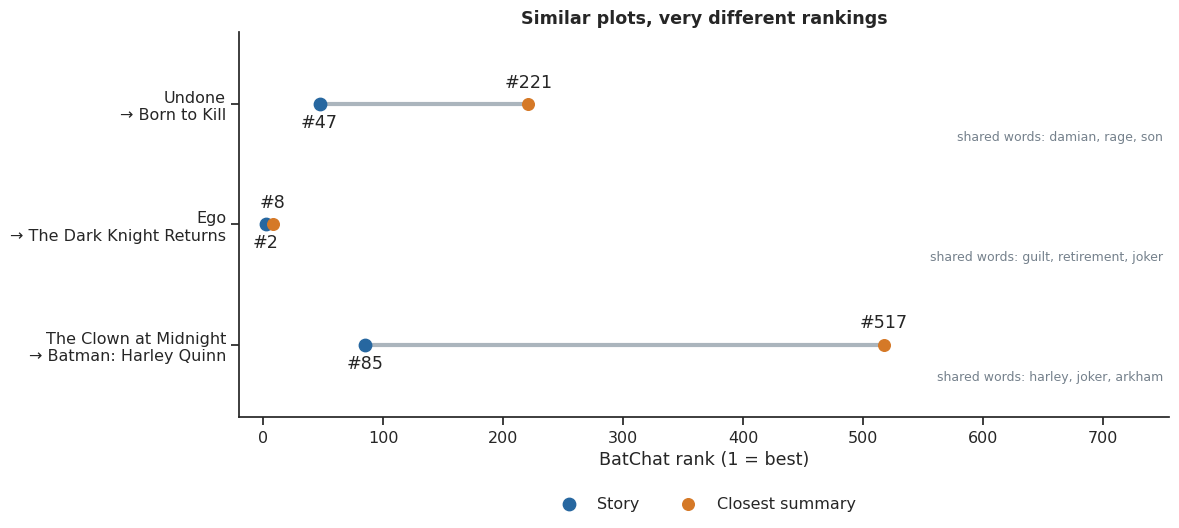

In [9]:
has_text = np.flatnonzero(X.plot_text.str.split().str.len().ge(200))
words = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.9, sublinear_tf=True)
vectors = words.fit_transform(X.plot_text.iloc[has_text])
similarity = cosine_similarity(vectors)
pairs = []
for title in ["Undone", "Ego", "The Clown at Midnight"]:
    i = int(np.flatnonzero(stories.title.iloc[has_text].eq(title))[0])
    scores = np.where(groups[has_text] == groups[has_text[i]], -1, similarity[i])
    j = int(scores.argmax())
    shared = vectors[i].multiply(vectors[j]).toarray().ravel()
    pairs.append(
        {
            "story": title,
            "story_rank": int(y[has_text[i]]),
            "closest": stories.title.iloc[has_text[j]],
            "closest_rank": int(y[has_text[j]]),
            "shared_words": ", ".join(words.get_feature_names_out()[np.argsort(-shared)[:3]]),
        }
    )
pairs = pd.DataFrame(pairs)

fig, ax = plt.subplots(figsize=(12, 5))
for pos, row in pairs.iterrows():
    ax.plot([row.story_rank, row.closest_rank], [pos, pos], color="#ABB5BD", lw=3, zorder=1)
    ax.annotate(
        f"#{row.story_rank}",
        (row.story_rank, pos),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
    )
    ax.annotate(
        f"#{row.closest_rank}",
        (row.closest_rank, pos),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
    )
    ax.text(
        N + 10, pos + 0.3, f"shared words: {row.shared_words}", ha="right", fontsize=9, color=GREY
    )
ax.scatter(pairs.story_rank, pairs.index, color=BLUE, s=80, zorder=3, label="Story")
ax.scatter(pairs.closest_rank, pairs.index, color=ORANGE, s=70, zorder=3, label="Closest summary")
ax.set(
    yticks=pairs.index,
    yticklabels=[fill(r.story, 25) + "\n→ " + fill(r.closest, 25) for r in pairs.itertuples()],
    xlim=(-20, N + 15),
    ylim=(len(pairs) - 0.4, -0.6),
    xlabel="BatChat rank (1 = best)",
    title="Similar plots, very different rankings",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.show()

*Undone* finds *Born to Kill* through **Damian, rage, and son**: ranked **#47** and **#221**. *The Clown at Midnight* finds *Batman: Harley Quinn* through **Harley, Joker, and Arkham**: **#85** and **#517**.

And one pairing any fan would sign off on: **guilt, retirement, and Joker** link *Ego* (**#2**) with *The Dark Knight Returns* (**#8**).

## Takeaways

- Names and dates predict a little of BatChat's taste: about 8% less error than guessing the middle.
- Characters, awards, and plot summaries add almost nothing on top.
- The misses are the fun part. *Undone*, *The Last Crusade*, and *White Knight* show that execution matters more than any column in this dataset.
- Plot words are better at finding books to compare than at ranking them.

I'd put *Undone* beside *Born to Kill* and look at how each handles Damian's anger. The shared words give a reason to read them together; the ranking gap gives something to argue about.

**Next:** [Who Gets the Good Batman Stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [BatChat vs the Crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.